# 📄 UTS Praktikum Visi Komputer B | Pemindai Dokumen Otomatis

### Anggota kelompok

1. Mahda Annisa (2408107010036)
2. M. Rayan Zishan (2408107010063)
3. Zanna Zikraana (2408107010094)
4. Cut Farah Salsabila (2408107010100)



## 🎯 Deskripsi Proyek

Program ini mengubah foto kertas dokumen yang diambil miring menjadi citra hasil scan tampak atas yang hitam-putih, mirip hasil scanner profesional.

Pipeline utama:
1. Deteksi 4 sudut kertas secara otomatis (tanpa klik manual)
2. Warp perspektif → kertas diluruskan jadi tampak atas

---

## 🎓 Capaian Pembelajaran

Setelah mengerjakan proyek ini, mahasiswa mampu:

- Menerapkan blur + Canny untuk deteksi tepi
- Menggunakan findContours + approxPolyDP untuk menemukan kontur segi empat
- Menerapkan getPerspectiveTransform + warpPerspective untuk koreksi perspektif
- Membandingkan threshold global (Otsu) vs adaptive threshold (Mean vs Gaussian)
- Mengevaluasi performa program terhadap ground truth yang sudah dianotasi manual

---

## 📚 Materi Wajib yang Diterapkan

| Materi | Pertemuan | Dipakai di |
|--------|-----------|------------|
| Blur + Canny | 4 | Deteksi tepi kertas |
| findContours + approxPolyDP | 4 | Cari 4 sudut kertas |
| getPerspectiveTransform / warpPerspective | 4 | Luruskan kertas ke tampak atas |
| Adaptive Threshold | 4 | Binarisasi akhir |

---

## 📸 Dataset

Total: X foto

5 jenis dokumen:
- Halaman buku
- Struk belanja
- Kertas tugas tulisan tangan
- Brosur
- Fotokopi

## Variasi Kategori Pengambilan Dataset

| Kategori | Jumlah | Deskripsi |
|----------|:---:|-----------|
| `ideal` | 5 | Dokumen difoto dengan cahaya terang dan merata, latar polos, serta objek terlihat jelas. |
| `cahaya` | 4 | Dokumen difoto dengan pencahayaan redup, cahaya dari samping yang menimbulkan bayangan, atau cahaya luar ruangan. |
| `sudut` | 12 | Dokumen difoto dengan posisi atau sudut berbeda, seperti diputar, digeser, atau diambil dari sudut miring. |
| `sulit` | 8 | Dokumen menggunakan latar bertekstur atau ramai, saling bertumpuk, terlipat, atau sebagian tertutup. |
| Total | 29 | 29 gambar dengan variasi kondisi pengambilan. |




Ground truth: `ground_truth.csv` — mencatat apakah 4 sudut kertas terlihat penuh (`ya`/`tidak`).




## 1. Setup Path Folder
Menentukan lokasi folder proyek, folder dataset, file `ground_truth.csv`, dan folder output untuk menyimpan hasil pemrosesan gambar.

In [37]:
# Setup Path Relatif
from pathlib import Path
import os

BASE_DIR = Path.cwd()
if not (BASE_DIR / "dataset").exists() and (BASE_DIR.parent / "dataset").exists():
    BASE_DIR = BASE_DIR.parent

DATASET_DIR = BASE_DIR / "dataset"
CSV_PATH    = DATASET_DIR / "ground_truth.csv"
OUTPUT_DIR  = BASE_DIR / "output"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def find_images(root):
    """Scan rekursif semua gambar di dataset (termasuk subfolder)."""
    root = Path(root)
    if not root.exists():
        return []
    return sorted([
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ])

# Scan semua gambar
image_files = find_images(DATASET_DIR)
print(f"Total gambar ditemukan: {len(image_files)}")

# Build mapping: nama file → path lengkap
# Kalau ada duplikat nama di subfolder berbeda, yang terakhir menang
IMAGE_MAP = {p.name: p for p in image_files}

print(f"Unique filename di map: {len(IMAGE_MAP)}")

# Cek duplikat (kalau ada, warning)
from collections import Counter

nama_counter = Counter([p.name for p in image_files])
duplikat = {n: c for n, c in nama_counter.items() if c > 1}

if duplikat:
    print("⚠️ Ada nama file duplikat:")
    for n, c in duplikat.items():
        print(f"   {n}: {c} kemunculan")
        for p in image_files:
            if p.name == n:
                print(f"     - {p.relative_to(DATASET_DIR)}")
else:
    print("✅ Tidak ada duplikat nama file")

Total gambar ditemukan: 31
Unique filename di map: 31
✅ Tidak ada duplikat nama file


In [38]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import csv

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("Folder dataset:", DATASET_DIR)
print("CSV tersedia  :", CSV_PATH)
print("Folder output :", OUTPUT_DIR)

Folder dataset: c:\Users\asus\OneDrive\Dokumen\Prak Viskom\UTS_VisKom_Kelompok03\dataset
CSV tersedia  : c:\Users\asus\OneDrive\Dokumen\Prak Viskom\UTS_VisKom_Kelompok03\dataset\ground_truth.csv
Folder output : c:\Users\asus\OneDrive\Dokumen\Prak Viskom\UTS_VisKom_Kelompok03\output


In [39]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 7)
plt.rcParams["image.cmap"] = "gray"
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 5.0.0
NumPy: 2.5.4


## 2. Fungsi bantu

Gambar dibaca menggunakan `np.fromfile` dan `cv2.imdecode` agar nama file yang mengandung spasi atau karakter non-ASCII tetap bisa dibaca. Untuk pemrosesan, sisi terpanjang foto dibatasi sekitar 1100 piksel agar proses lebih ringan.

In [40]:
def read_image(path):
    """Baca gambar yang juga mendukung nama file dengan karakter khusus."""
    path = Path(path)
    try:
        raw = np.fromfile(str(path), dtype=np.uint8)
        if raw.size == 0:
            return None
        return cv2.imdecode(raw, cv2.IMREAD_COLOR)
    except (OSError, ValueError):
        return None


def show_bgr(image, title="", ax=None, figsize=(6, 5)):
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    if image is None:
        ax.text(0.5, 0.5, "Gambar tidak tersedia", ha="center", va="center")
    else:
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
    return ax


def show_gray(image, title="", ax=None, figsize=(6, 5)):
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    if image is None:
        ax.text(0.5, 0.5, "Gambar tidak tersedia", ha="center", va="center")
    else:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
    return ax


def resize_for_detection(image, max_side=1100):
    h, w = image.shape[:2]
    scale = min(1.0, max_side / max(h, w))
    if scale < 1:
        resized = cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    else:
        resized = image.copy()
    return resized, scale


def order_points(points):
    pts = np.asarray(points, dtype=np.float32).reshape(4, 2)
    sums = pts.sum(axis=1)
    diffs = np.diff(pts, axis=1).reshape(-1)
    return np.array([pts[np.argmin(sums)], pts[np.argmin(diffs)],
                     pts[np.argmax(sums)], pts[np.argmax(diffs)]], dtype=np.float32)

## 3. Memuat dataset dan ground truth

Notebook mencari gambar di folder kondisi (`ideal`, `cahaya`, `sudut`, `sulit`) dan juga mendukung foto yang langsung diletakkan di `dataset/`. Kolom CSV yang digunakan adalah `filename`, `kategori`, dan `sudut_terlihat_penuh`; kolom `jenis_dokumen` bersifat tambahan. Pastikan setiap foto memiliki satu baris CSV dan kategori konsisten.

In [41]:
def find_images(root):
    if not root.exists():
        return []
    return sorted([p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS
                   and p.name.lower() != "ground_truth.csv"])

image_files = find_images(DATASET_DIR)

def load_ground_truth(csv_path):
    rows = []
    if not csv_path.exists():
        print("PERINGATAN: ground_truth.csv belum ditemukan.")
        return rows
    with csv_path.open("r", encoding="utf-8-sig", newline="") as f:
        reader = csv.DictReader(f)
        for row in reader:
            cleaned = {str(k).strip(): (v.strip() if isinstance(v, str) else v) for k, v in row.items() if k}
            if cleaned.get("filename"):
                rows.append(cleaned)
    return rows

ground_truth = load_ground_truth(CSV_PATH)
print("Jumlah foto ditemukan:", len(image_files))
print("Jumlah baris ground truth valid:", len(ground_truth))
print("Contoh baris CSV:")
for row in ground_truth[:5]:
    print(row)

# Ringkasan jumlah foto yang terbaca
readable = []
for path in image_files:
    if read_image(path) is not None:
        readable.append(path)
    else:
        print("Gagal membaca gambar:", path)
print(f"Foto terbaca: {len(readable)} dari {len(image_files)}")


Jumlah foto ditemukan: 31
Jumlah baris ground truth valid: 31
Contoh baris CSV:
{'filename': 'buku_mahda_01.jpeg', 'kategori': 'cahaya', 'sudut_terlihat_penuh': 'ya', 'jenis_dokumen': 'buku'}
{'filename': 'fotocopy_mahda_01.jpeg', 'kategori': 'cahaya', 'sudut_terlihat_penuh': 'ya', 'jenis_dokumen': 'fotocopy'}
{'filename': 'struk_mahda_01.jpeg', 'kategori': 'cahaya', 'sudut_terlihat_penuh': 'ya', 'jenis_dokumen': 'struk'}
{'filename': 'tulis_mahda_01.jpeg', 'kategori': 'cahaya', 'sudut_terlihat_penuh': 'ya', 'jenis_dokumen': 'tulis_tangan'}
{'filename': 'fotocopy_rayan_01.jpg', 'kategori': 'sulit', 'sudut_terlihat_penuh': 'ya', 'jenis_dokumen': 'fotocopy'}
Foto terbaca: 31 dari 31


### Contoh satu gambar untuk setiap kondisi

Satu gambar per kondisi ditampilkan dalam satu figure agar mudah membandingkan kondisi ideal, bayangan/cahaya, sudut miring besar, dan sulit. Nama folder digunakan sebagai kategori; jika gambar berada langsung di folder dataset, kategori diambil dari CSV.

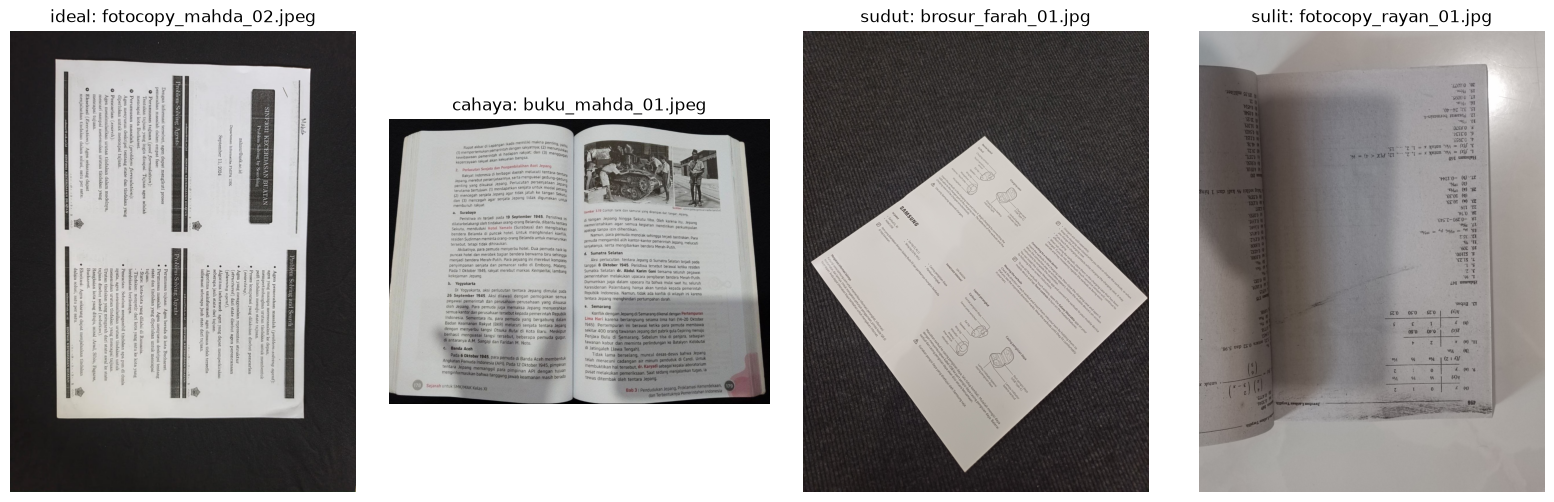

In [42]:
gt_by_name = {r.get("filename", "").strip(): r for r in ground_truth}
def category_for(path):
    row = gt_by_name.get(path.name, {})
    cat = row.get("kategori", "").strip().lower()
    if cat:
        return cat
    return path.parent.name.lower() if path.parent != DATASET_DIR else "tidak diketahui"

wanted_categories = ["ideal", "cahaya", "sudut", "sulit"]
chosen = {}
for path in readable:
    cat = category_for(path)
    # Samakan beberapa variasi penamaan kategori.
    if cat in {"bayangan", "pencahayaan", "cahaya_bayangan"}:
        cat = "cahaya"
    elif cat in {"miring_besar", "sudut_miring", "rotasi"}:
        cat = "sudut"
    if cat in wanted_categories and cat not in chosen:
        chosen[cat] = path

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for cat, ax in zip(wanted_categories, axes):
    path = chosen.get(cat)
    if path:
        show_bgr(read_image(path), f"{cat}: {path.name}", ax=ax)
    else:
        ax.text(0.5, 0.5, f"Belum ada contoh\n{cat}", ha="center", va="center")
        ax.set_title(cat)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Deteksi empat sudut dokumen otomatis

Tahapan: grayscale → Gaussian blur `(5,5)` untuk mengurangi noise → Canny `(50,150)` untuk menemukan tepi → kontur terbesar → `approxPolyDP` untuk menyederhanakan kontur. Beberapa nilai epsilon dicoba berurutan agar kontur dokumen yang hampir berbentuk persegi panjang tidak langsung terlewat. Jika sudut tidak ditemukan, fungsi mengembalikan `None` dan tidak membuat warp palsu.

In [43]:
# Deteksi 4 sudut
A4_RATIO = 297 / 210
def _sudut_internal_quad(pts):
    """Hitung 4 sudut internal quad (derajat). pts harus sudah urut."""
    angles = []
    for i in range(4):
        p0, p1, p2 = pts[(i-1) % 4], pts[i], pts[(i+1) % 4]
        v1, v2 = p0 - p1, p2 - p1
        cos_a = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-8)
        angles.append(np.degrees(np.arccos(np.clip(cos_a, -1, 1))))
    return np.array(angles)

def _skor_quad_v2(corners_small, area_ratio, image_w, image_h):
    """
    Skor berbasis BENTUK, bukan rasio A4.
    Cocok untuk foto miring karena proyeksi perspektif mengubah rasio.
    """
    pts = corners_small.reshape(4, 2).astype(np.float32)

    # 1. Harus convex
    if not cv2.isContourConvex(pts.reshape(-1, 1, 2).astype(np.int32)):
        return -1

    # 2. Sudut internal wajar (hindari quad degenerasi / garis)
    angles = _sudut_internal_quad(pts)
    if np.any(angles < 45) or np.any(angles > 135):
        return -1
    angle_score = np.clip(1 - np.std(angles) / 45, 0, 1)

    # 3. Solidity: seberapa "rectangle" quad ini
    quad_area = cv2.contourArea(pts.reshape(-1, 1, 2))
    rect = cv2.minAreaRect(pts.reshape(-1, 1, 2))
    rect_area = rect[1][0] * rect[1][1]
    if rect_area < 1:
        return -1
    solidity = quad_area / rect_area  # 1.0 = rectangle sempurna

    # 4. Area: tidak terlalu kecil / tidak menutupi seluruh foto
    if area_ratio < 0.05:
        return -1
    if area_ratio > 0.95:
        area_score = 0.3   # kemungkinan frame foto, bukan kertas
    elif area_ratio > 0.85:
        area_score = 0.7
    else:
        area_score = 1.0

    # 5. Penalti jika ≥3 titik menempel tepi frame
    m = 2
    n_touch = sum(1 for x, y in pts
                  if x <= m or x >= image_w - m - 1
                  or y <= m or y >= image_h - m - 1)
    border_penalty = 0.7 if n_touch >= 3 else 1.0

    return (0.40 * solidity + 0.30 * angle_score + 0.30 * area_score) * border_penalty


def _preprocess_variant(image, variant="clahe_normal"):
    """Grayscale -> peningkatan kontras opsional -> Gaussian blur -> Canny -> close."""
    if image is None:
        raise ValueError("Gambar tidak berhasil dibaca.")
    resized, scale = resize_for_detection(image)
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

    if variant == "clahe_strong":
        gray_eq = cv2.createCLAHE(clipLimit=4.0, tileGridSize=(8, 8)).apply(gray)
    elif variant == "clahe_tile_small":
        gray_eq = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4)).apply(gray)
    elif variant == "bilateral":
        gray_eq = cv2.bilateralFilter(gray, 9, 75, 75)
    elif variant == "tophat":
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
        top_hat = cv2.morphologyEx(gray, cv2.MORPH_TOPHAT, kernel)
        black_hat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
        gray_eq = cv2.normalize(cv2.subtract(cv2.add(gray, top_hat), black_hat), None, 0, 255, cv2.NORM_MINMAX)
    else:
        gray_eq = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)

    blurred = cv2.GaussianBlur(gray_eq, (5, 5), 0)

    if variant == "adaptive_canny":
        # Adaptive threshold membantu saat kontras tepi rendah; Canny tetap dipakai.
        binary = cv2.adaptiveThreshold(
            gray_eq, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY, 51, 10
        )
        edges = cv2.Canny(binary, 50, 150)
    else:
        # Canny dengan ambang otomatis yang dibatasi agar tidak terlalu ekstrem.
        median = float(np.median(blurred))
        low = int(max(20, 0.66 * median))
        high = int(min(240, max(low + 30, 1.33 * median)))
        edges = cv2.Canny(blurred, low, high)

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    edges = cv2.dilate(edges, kernel, iterations=1)
    edges_closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel, iterations=2)
    return resized, scale, gray_eq, blurred, edges, edges_closed

def _skor_quad(corners_small, area_ratio, image_w=None, image_h=None):
    """
    Skor LUNAK. Tolak:
    - Quad degenerasi (sisi < 5 px)
    - Quad ≥2 titik di frame (kertas menyatu dengan frame)
    - Quad area > 0.92 (kemungkinan frame/meja, bukan kertas)
    Beri skor rendah (tapi tidak -1) untuk area 0.85–0.92.
    """
    pts = corners_small.reshape(4, 2)
    w_top    = np.linalg.norm(pts[1] - pts[0])
    w_bottom = np.linalg.norm(pts[2] - pts[3])
    h_left   = np.linalg.norm(pts[3] - pts[0])
    h_right  = np.linalg.norm(pts[2] - pts[1])
    w = (w_top + w_bottom) / 2
    h = (h_left + h_right) / 2
    if w < 5 or h < 5:
        return -1

    # HARD REJECT: area > 0.92 = kemungkinan frame/meja
    # Kertas jarang sekali >92% frame, dan kalau memang iya, itu tanda
    # kontur salah (frame atau bayangan di tepi). Lebih baik fallback.
    if area_ratio > 0.92:
        return -1

    # HARD REJECT: ≥2 titik di frame = kertas menyatu frame
    if image_w is not None and image_h is not None:
        margin = 0.02
        x_min = margin * image_w
        x_max = (1 - margin) * image_w
        y_min = margin * image_h
        y_max = (1 - margin) * image_h
        n_touch = sum(
            1 for x, y in pts
            if x <= x_min or x >= x_max or y <= y_min or y >= y_max
        )
        if n_touch >= 2:
            return -1

    ratio = max(w, h) / min(w, h)
    rasio_score = max(0.0, 1.0 - abs(ratio - A4_RATIO) / A4_RATIO)

    if area_ratio < 0.05:
        area_score = 0.0
    elif area_ratio < 0.30:
        area_score = area_ratio / 0.30
    elif area_ratio <= 0.85:
        area_score = 1.0
    else:
        # 0.85–0.92: transisi turun
        area_score = 1.0 - (area_ratio - 0.85) / 0.07 * 0.7

    return 0.55 * rasio_score + 0.45 * area_score

def _paksa_quad(contour):
    """
    Kalau approxPolyDP biasa gagal dapat 4 titik,
    coba convex hull + approxPolyDP berulang.
    """
    hull = cv2.convexHull(contour)
    peri = cv2.arcLength(hull, True)
    for eps in (0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10):
        ap = cv2.approxPolyDP(hull, eps * peri, True)
        if len(ap) == 4 and cv2.isContourConvex(ap):
            return ap.reshape(4, 2).astype(np.float32)
    return None

def _kumpulkan_kandidat(edges_closed, image_area,
                        min_area_ratio=0.02, max_area_ratio=0.95,
                        epsilon_values=(0.01, 0.015, 0.02, 0.025, 0.03,
                                        0.04, 0.05, 0.06, 0.08)):
    """Kumpulkan kandidat quad dari kontur Canny; jangan otomatis menganggap frame foto sebagai kertas."""
    h, w = edges_closed.shape[:2]
    pad = max(8, int(min(h, w) * 0.015))
    padded = cv2.copyMakeBorder(edges_closed, pad, pad, pad, pad,
                                cv2.BORDER_CONSTANT, value=0)
    ph, pw = padded.shape[:2]
    padded_area = ph * pw
    candidates = []

    for mode in (cv2.RETR_LIST, cv2.RETR_EXTERNAL):
        contours, _ = cv2.findContours(padded.copy(), mode, cv2.CHAIN_APPROX_SIMPLE)
        contours = sorted(contours, key=cv2.contourArea, reverse=True)

        for contour in contours[:80]:
            area = cv2.contourArea(contour)
            ratio_padded = area / padded_area
            if ratio_padded < min_area_ratio or ratio_padded > max_area_ratio:
                continue
            perimeter = cv2.arcLength(contour, True)
            if perimeter < 80:
                continue

            quads = []
            for eps in epsilon_values:
                approx = cv2.approxPolyDP(contour, eps * perimeter, True)
                if len(approx) == 4 and cv2.isContourConvex(approx):
                    quads.append((approx.reshape(4, 2).astype(np.float32), eps))
            # Convex hull membantu bila kontur sedikit bergerigi/terputus.
            if not quads:
                hull = cv2.convexHull(contour)
                hp = cv2.arcLength(hull, True)
                for eps in (0.015, 0.02, 0.03, 0.04, 0.06, 0.08):
                    approx = cv2.approxPolyDP(hull, eps * hp, True)
                    if len(approx) == 4 and cv2.isContourConvex(approx):
                        quads.append((approx.reshape(4, 2).astype(np.float32), f"hull-{eps}"))
                        break

            for pts_pad, eps_used in quads:
                pts = pts_pad.copy()
                pts[:, 0] -= pad
                pts[:, 1] -= pad
                pts[:, 0] = np.clip(pts[:, 0], 0, w - 1)
                pts[:, 1] = np.clip(pts[:, 1], 0, h - 1)
                pts = order_points(pts)
                quad_area = abs(cv2.contourArea(pts.reshape(-1, 1, 2)))
                area_ratio = quad_area / image_area
                if area_ratio < min_area_ratio or area_ratio > max_area_ratio:
                    continue

                sides = np.array([
                    np.linalg.norm(pts[1]-pts[0]),
                    np.linalg.norm(pts[2]-pts[1]),
                    np.linalg.norm(pts[3]-pts[2]),
                    np.linalg.norm(pts[0]-pts[3])
                ])
                if sides.min() < 12:
                    continue

                angles = _sudut_internal_quad(pts)
                if np.any(angles < 25) or np.any(angles > 155):
                    continue

                # Hindari kontur frame: penalti berdasarkan titik yang sangat dekat tepi.
                margin_x, margin_y = max(3, int(w*0.008)), max(3, int(h*0.008))
                touches = sum(
                    (x <= margin_x or x >= w-1-margin_x or
                     y <= margin_y or y >= h-1-margin_y)
                    for x, y in pts
                )
                border_score = 1.0 if touches == 0 else (0.65 if touches == 1 else 0.15)

                # Bentuk quadrilateral dan area menjadi skor utama; rasio A4 bukan syarat keras
                # karena perspektif dan jenis dokumen dapat mengubah proporsi yang terlihat.
                rect = cv2.minAreaRect(pts.reshape(-1, 1, 2).astype(np.float32))
                rect_area = max(rect[1][0] * rect[1][1], 1.0)
                solidity = min(1.0, quad_area / rect_area)
                area_score = min(1.0, area_ratio / 0.30)
                angle_score = max(0.0, 1.0 - np.std(angles) / 55.0)
                score = (0.35*solidity + 0.30*angle_score + 0.35*area_score) * border_score

                candidates.append({
                    "skor": float(score), "corners": pts, "contour": contour,
                    "epsilon": eps_used, "area": quad_area,
                    "area_ratio": area_ratio
                })

    # Hilangkan kandidat duplikat yang hampir sama, lalu urutkan berdasarkan skor.
    candidates.sort(key=lambda item: item["skor"], reverse=True)
    unique = []
    for item in candidates:
        if not any(np.mean(np.linalg.norm(item["corners"] - old["corners"], axis=1)) < 12
                   for old in unique):
            unique.append(item)
        if len(unique) >= 20:
            break
    return unique

def detect_document_corners(image, min_area_ratio=0.02, max_area_ratio=0.95,
                            epsilon_values=(0.01, 0.015, 0.02, 0.025, 0.03,
                                            0.04, 0.05, 0.06, 0.08)):
    """Deteksi otomatis 4 sudut menggunakan preprocessing + Canny + contours + approxPolyDP."""
    if image is None:
        raise ValueError("Gambar tidak berhasil dibaca.")

    variants = ["clahe_normal", "clahe_strong", "clahe_tile_small",
                "bilateral", "tophat", "adaptive_canny"]
    all_candidates = []
    last_state = None

    for variant in variants:
        resized, scale, gray_eq, blurred, edges, edges_closed = _preprocess_variant(image, variant)
        last_state = (resized, scale, gray_eq, blurred, edges, edges_closed)
        image_area = resized.shape[0] * resized.shape[1]

        candidates = _kumpulkan_kandidat(
            edges_closed, image_area, min_area_ratio, max_area_ratio, epsilon_values
        )
        for candidate in candidates:
            candidate = candidate.copy()
            candidate["variant"] = variant
            candidate["corners_small"] = candidate["corners"].copy()
            candidate["corners"] = candidate["corners"] / scale
            candidate.update({
                "resized": resized, "gray": gray_eq, "blurred": blurred,
                "edges": edges, "edges_closed": edges_closed
            })
            all_candidates.append(candidate)

    if all_candidates:
        # Variasi preprocessing dapat menemukan kontur yang sama; pilih skor terbaik.
        all_candidates.sort(key=lambda item: item["skor"], reverse=True)
        best = all_candidates[0]
        if best["skor"] >= 0.38:
            best["epsilon_used"] = best["epsilon"]
            return best

    resized, scale, gray_eq, blurred, edges, edges_closed = last_state
    return {
        "corners": None, "corners_small": None, "resized": resized,
        "gray": gray_eq, "blurred": blurred, "edges": edges,
        "edges_closed": edges_closed, "contour": None,
        "epsilon_used": None, "area_ratio": None, "variant": None, "skor": -1
    }


In [44]:
# Warp + Threshold + Pipeline

def warp_kertas(image_bgr, points, lebar_output=1000):
    pts = order_points(points)

    # Validasi: quad harus convex & sudut wajar
    if not cv2.isContourConvex(pts.reshape(-1, 1, 2).astype(np.int32)):
        return None
    angles = _sudut_internal_quad(pts)
    if np.any(angles < 40) or np.any(angles > 140):
        return None

    # Estimasi lebar & tinggi quad sumber
    w = (np.linalg.norm(pts[1]-pts[0]) + np.linalg.norm(pts[2]-pts[3])) / 2
    h = (np.linalg.norm(pts[3]-pts[0]) + np.linalg.norm(pts[2]-pts[1])) / 2
    if w < 10 or h < 10:
        return None

    # Orientasi: portrait default, landscape hanya jika jelas lebih lebar
    is_landscape = w > h * 1.15
    lebar = int(lebar_output)
    tinggi = int(round(lebar / A4_RATIO)) if is_landscape else int(round(lebar * A4_RATIO))

    dst = np.array([[0, 0], [lebar-1, 0],
                    [lebar-1, tinggi-1], [0, tinggi-1]], dtype=np.float32)
    M = cv2.getPerspectiveTransform(pts.astype(np.float32), dst)
    warped = cv2.warpPerspective(image_bgr, M, (lebar, tinggi),
                                 flags=cv2.INTER_CUBIC,
                                 borderMode=cv2.BORDER_REPLICATE)

    # Sanity check: tolak hasil warp yang kosong/rusak
    if warped.std() < 5:
        return None
    return warped

def threshold_otsu(gray):
    """Threshold global Otsu."""
    _, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return binary


def threshold_adaptive_mean(gray, block_size=31, C=10):
    """Adaptive threshold dengan MEAN."""
    if block_size % 2 == 0:
        block_size += 1
    return cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                 cv2.THRESH_BINARY, block_size, C)


def threshold_adaptive_gaussian(gray, block_size=31, C=10):
    """Adaptive threshold dengan GAUSSIAN."""
    if block_size % 2 == 0:
        block_size += 1
    return cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, block_size, C)


def threshold_camscanner(gray):
    """
    'Mode CamScanner': bilateral (halus tapi tepi teks tetap tajam)
    + adaptive threshold + pembersihan noise kecil.
    """
    # 1. Bilateral: mengurangi noise/toner fotokopi, teks tetap tajam
    smooth = cv2.bilateralFilter(gray, d=9, sigmaColor=75, sigmaSpace=75)
    # 2. CLAHE ringan: atasi bayangan
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    smooth = clahe.apply(smooth)
    # 3. Adaptive threshold
    binary = cv2.adaptiveThreshold(smooth, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY, 25, 10)
    # 4. Bersihkan bintik kecil
    kernel = np.ones((2, 2), np.uint8)
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
    # 5. Tutup celah kecil di teks
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    # 6. Median blur halus (opsional, bikin tepi teks lebih rapi)
    binary = cv2.medianBlur(binary, 3)
    return binary


def pipeline(path, metode_threshold="camscanner", lebar_output=1000):
    """Load → deteksi → warp → threshold. Return dict berisi semua tahap."""
    img = read_image(path)
    if img is None:
        return {"error": "gagal load gambar", "path": path}

    det = detect_document_corners(img)
    if det["corners"] is None:
        return {"error": "sudut tidak terdeteksi", "path": path,
                "original": img, "detection": det}

    warped = warp_kertas(img, det["corners"], lebar_output=lebar_output)
    if warped is None:
        return {"error": "warp gagal", "path": path, "original": img,
                "detection": det}

    gray = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)

    if metode_threshold == "otsu":
        binary = threshold_otsu(gray)
    elif metode_threshold == "adaptive_mean":
        binary = threshold_adaptive_mean(gray)
    elif metode_threshold == "adaptive_gaussian":
        binary = threshold_adaptive_gaussian(gray)
    else:  # camscanner
        binary = threshold_camscanner(gray)

    return {
        "path": path,
        "original": img,
        "detection": det,
        "warped": warped,
        "gray": gray,
        "binary": binary,
    }

## 5. Uji pipeline langkah demi langkah

Pilih satu foto yang tersedia. Figure berikut menunjukkan citra asli, grayscale, blur, Canny, kontur kandidat, hasil warp, dan hasil biner. Apabila empat sudut tidak terdeteksi, notebook menampilkan tahap tepi untuk membantu analisis, bukan memaksakan hasil.

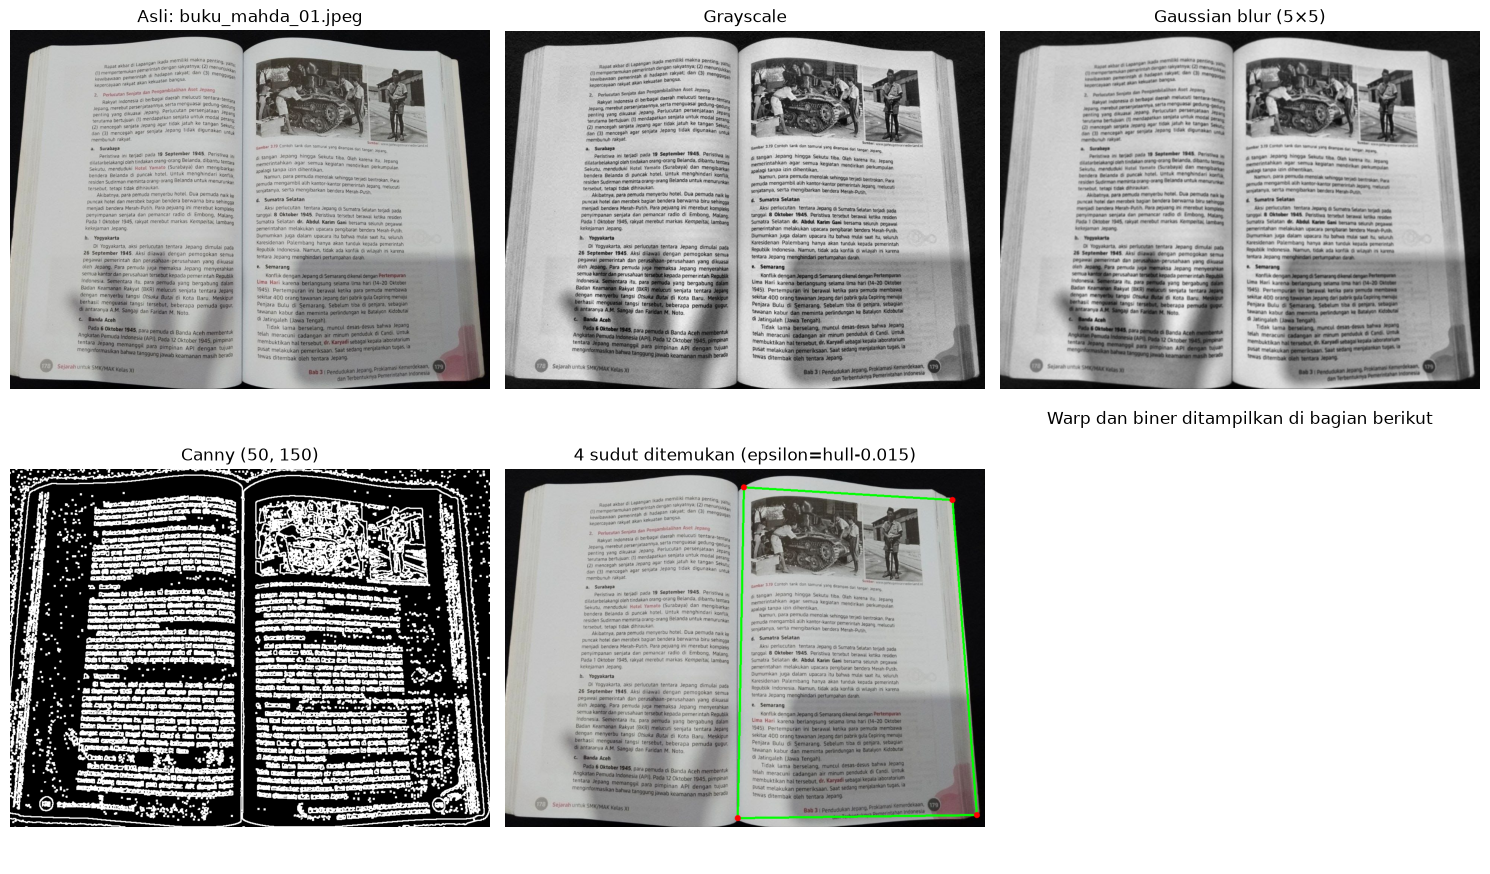

In [45]:
if readable:
    SAMPLE_PATH = readable[0]
    sample = read_image(SAMPLE_PATH)
    detected = detect_document_corners(sample)
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    show_bgr(sample, f"Asli: {SAMPLE_PATH.name}", axes[0, 0])
    show_gray(detected["gray"], "Grayscale", axes[0, 1])
    show_gray(detected["blurred"], "Gaussian blur (5×5)", axes[0, 2])
    show_gray(detected["edges"], "Canny (50, 150)", axes[1, 0])
    contour_view = detected["resized"].copy()
    if detected["corners_small"] is not None:
        pts = detected["corners_small"].astype(np.int32).reshape(-1, 1, 2)
        cv2.polylines(contour_view, [pts], True, (0, 255, 0), 3)
        for x, y in detected["corners_small"].astype(int):
            cv2.circle(contour_view, (x, y), 7, (0, 0, 255), -1)
        show_bgr(contour_view, f"4 sudut ditemukan (epsilon={detected['epsilon_used']})", axes[1, 1])
        warped = None
        # Fungsi warp dibuat pada bagian berikut; untuk figure ini dipanggil setelah fungsi tersedia.
    else:
        show_bgr(contour_view, "Kontur kandidat: empat sudut tidak ditemukan", axes[1, 1])
    axes[1, 2].axis("off")
    axes[1, 2].set_title("Warp dan biner ditampilkan di bagian berikut")
    plt.tight_layout()
    plt.show()
else:
    print("Belum ada gambar. Letakkan foto ke folder dataset/ lalu jalankan ulang.")

## 6. Meluruskan dokumen ke rasio A4

Rasio A4 potret adalah `210:297`. Ukuran 840 × 1188 piksel mempertahankan rasio tersebut. `getPerspectiveTransform` menghitung pemetaan dari empat sudut foto ke empat sudut kanvas, lalu `warpPerspective` menghasilkan tampilan dari atas.

Ukuran hasil: 840 x 1188
Rasio hasil: 0.70707
Rasio A4 potret: 0.70707
Rasio A4 lanskap: 1.41429


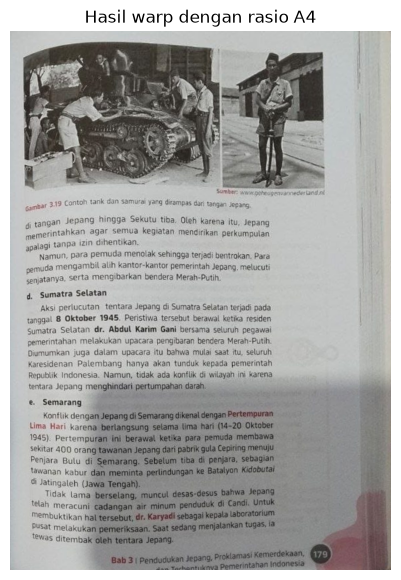

In [46]:
# Ukuran A4 dengan rasio 210:297
A4_WIDTH = 840
A4_HEIGHT = 1188
A4_RATIO = 210 / 297

def perspective_warp(image, corners, width=A4_WIDTH):
    """
    Meluruskan dokumen menggunakan empat titik sudut.
    Orientasi potret/lanskap dipilih berdasarkan bentuk dokumen.
    Rasio hasil selalu mengikuti rasio A4.
    """
    if image is None or corners is None or len(corners) != 4:
        return None

    src = order_points(corners).astype(np.float32)

    # Perkiraan lebar dan tinggi dokumen dari empat sisi
    lebar_atas = np.linalg.norm(src[1] - src[0])
    lebar_bawah = np.linalg.norm(src[2] - src[3])
    tinggi_kiri = np.linalg.norm(src[3] - src[0])
    tinggi_kanan = np.linalg.norm(src[2] - src[1])

    lebar_sumber = (lebar_atas + lebar_bawah) / 2
    tinggi_sumber = (tinggi_kiri + tinggi_kanan) / 2

    if lebar_sumber < 10 or tinggi_sumber < 10:
        return None

    # Pilih orientasi sesuai bentuk dokumen
    is_landscape = lebar_sumber > tinggi_sumber

    if is_landscape:
        out_width = int(round(width * 297 / 210))
        out_height = width
    else:
        out_width = width
        out_height = int(round(width * 297 / 210))

    # Titik tujuan pada kanvas A4
    dst = np.array([
        [0, 0],
        [out_width - 1, 0],
        [out_width - 1, out_height - 1],
        [0, out_height - 1]
    ], dtype=np.float32)

    matrix = cv2.getPerspectiveTransform(src, dst)

    warped = cv2.warpPerspective(
        image,
        matrix,
        (out_width, out_height),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_REPLICATE
    )

    return warped


# Uji warp pada sampel yang sudah digunakan di notebook
if readable:
    SAMPLE_PATH = readable[0]
    sample = read_image(SAMPLE_PATH)
    detected = detect_document_corners(sample)

    if detected["corners"] is not None:
        warped_sample = perspective_warp(
            sample, detected["corners"]
        )
        if warped_sample is not None:
            h, w = warped_sample.shape[:2]
            print("Ukuran hasil:", w, "x", h)
            print("Rasio hasil:", round(w / h, 5))
            print("Rasio A4 potret:", round(210 / 297, 5))
            print("Rasio A4 lanskap:", round(297 / 210, 5))
            show_bgr(
                warped_sample,
                "Hasil warp dengan rasio A4",
                figsize=(6, 7)
            )
        else:
            print("Warp gagal pada gambar sampel.")
    else:
        print("Empat sudut belum terdeteksi pada sampel.")
else:
    print("Belum ada foto yang bisa diuji.")


## 7. Thresholding agar tulisan lebih terbaca

Untuk bayangan atau pencahayaan tidak merata, satu ambang global Otsu dapat membuat sebagian teks hilang. Karena itu, sebelum threshold digunakan CLAHE untuk meningkatkan kontras lokal secara terbatas dan Gaussian blur ringan untuk mengurangi noise. Hasil adaptive Gaussian dipakai sebagai hasil scanner utama; Otsu dan adaptive mean tetap ditampilkan sebagai pembanding. Operasi morfologi ringan mengurangi bintik kecil tanpa sengaja menebalkan teks terlalu banyak.

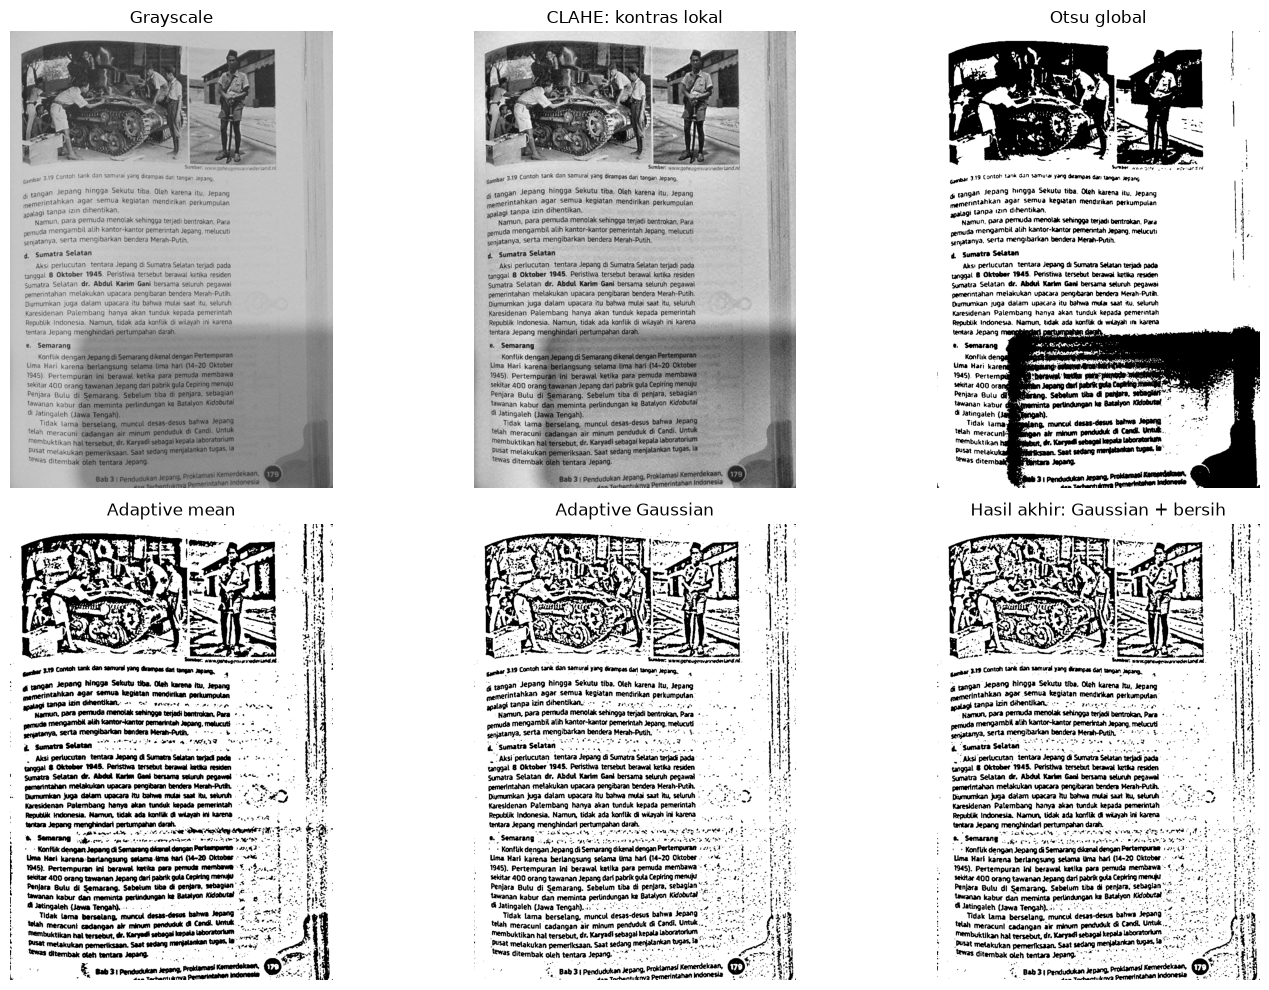

Ambang Otsu: 139


In [47]:
def enhance_document_color(warped):
    """Koreksi pencahayaan ringan tanpa mengubah geometri dokumen."""
    lab = cv2.cvtColor(warped, cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(lab)
    # Estimasi pencahayaan latar dengan Gaussian blur berukuran besar.
    k = max(31, (min(L.shape[:2]) // 8) | 1)
    background = cv2.GaussianBlur(L, (k, k), 0)
    background = np.maximum(background, 1)
    normalized = np.clip(L.astype(np.float32) * 140.0 / background, 0, 255).astype(np.uint8)
    normalized = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(normalized)
    return cv2.cvtColor(cv2.merge([normalized, a, b]), cv2.COLOR_LAB2BGR)


def make_threshold_comparison(warped, block_size=35, C=9, use_clahe=True):
    gray = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)
    if use_clahe:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        enhanced = clahe.apply(gray)
    else:
        enhanced = gray.copy()
    smooth = cv2.GaussianBlur(enhanced, (3, 3), 0)
    otsu_value, otsu = cv2.threshold(smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    adaptive_mean = cv2.adaptiveThreshold(smooth, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                          cv2.THRESH_BINARY, block_size, C)
    adaptive_gaussian = cv2.adaptiveThreshold(smooth, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                              cv2.THRESH_BINARY, block_size, C)
    # Bersihkan noise titik kecil dengan opening kernel 2x2; teks utama dipertahankan.
    kernel = np.ones((2, 2), np.uint8)
    adaptive_clean = cv2.morphologyEx(adaptive_gaussian, cv2.MORPH_OPEN, kernel, iterations=1)
    return {"gray": gray, "enhanced": enhanced, "otsu_value": otsu_value,
            "otsu": otsu, "adaptive_mean": adaptive_mean,
            "adaptive_gaussian": adaptive_gaussian, "final": adaptive_clean}

if readable and detected["corners"] is not None:
    threshold_results = make_threshold_comparison(warped_sample)
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    display_items = [("gray", "Grayscale"), ("enhanced", "CLAHE: kontras lokal"),
                     ("otsu", "Otsu global"), ("adaptive_mean", "Adaptive mean"),
                     ("adaptive_gaussian", "Adaptive Gaussian"), ("final", "Hasil akhir: Gaussian + bersih")]
    for ax, (key, title) in zip(axes.flat, display_items):
        show_gray(threshold_results[key], title, ax=ax)
    plt.tight_layout()
    plt.show()
    print("Ambang Otsu:", int(threshold_results["otsu_value"]))
else:
    print("Pilih foto yang berhasil di-warp untuk membandingkan threshold.")

## 8. Eksperimen epsilon pada `approxPolyDP`

Nilai epsilon menentukan toleransi penyederhanaan kontur. Nilai terlalu kecil dapat menghasilkan terlalu banyak titik, sedangkan nilai terlalu besar dapat menghilangkan bentuk sudut. Perbandingan di bawah memperlihatkan jumlah titik hasil pada kontur besar pertama.

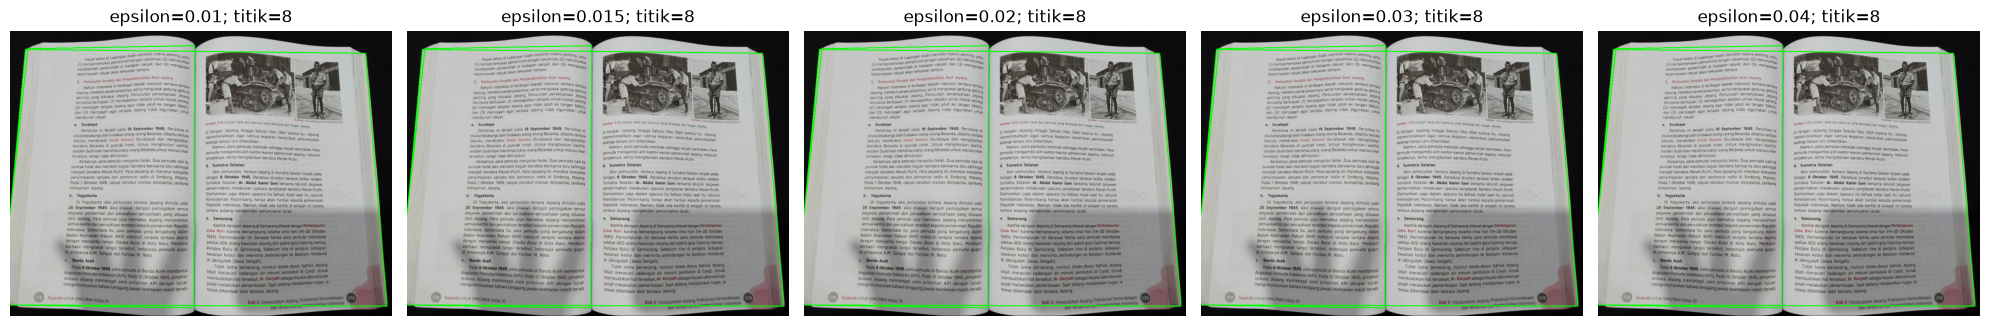

In [48]:
# Alias biar inspect_epsilon tetap jalan
def preprocess_edges(image):
    return _preprocess_variant(image, variant="clahe_normal")

def inspect_epsilon(image, epsilon_values=(0.01, 0.015, 0.02, 0.03, 0.04)):
    resized, _, _, _, _, edges_closed = preprocess_edges(image)
    contours, _ = cv2.findContours(edges_closed.copy(), cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)
    image_area = resized.shape[0] * resized.shape[1]
    contour = next((c for c in contours if cv2.contourArea(c) >= 0.08 * image_area), None)
    if contour is None:
        print("Tidak ditemukan kontur besar untuk eksperimen epsilon.")
        return
    perimeter = cv2.arcLength(contour, True)
    fig, axes = plt.subplots(1, len(epsilon_values), figsize=(4 * len(epsilon_values), 4))
    for ax, eps in zip(np.atleast_1d(axes), epsilon_values):
        approx = cv2.approxPolyDP(contour, eps * perimeter, True)
        view = resized.copy()
        cv2.polylines(view, [approx], True, (0, 255, 0), 2)
        show_bgr(view, f"epsilon={eps}; titik={len(approx)}", ax=ax)
    plt.tight_layout()
    plt.show()

if readable:
    SAMPLE_PATH = readable[0]
    inspect_epsilon(read_image(SAMPLE_PATH))
else:
    print("Eksperimen epsilon dilewati: belum ada gambar yang terbaca di dataset/.")

## 9. Proses seluruh dataset dan simpan hasil
Untuk setiap foto, notebook mencoba mendeteksi empat sudut, melakukan warp, lalu menyimpan hasil adaptive Gaussian sebagai citra biner. Jika deteksi gagal, status dicatat dan file hasil tidak dibuat. File hasil diberi nama berdasarkan foto asal.

Kolom four_corners_visible dari ground_truth.csv digunakan untuk mengevaluasi hasil secara sederhana, bukan untuk mengubah keputusan algoritma.

In [49]:
def process_one(
    image_path,
    epsilon_values=(0.01, 0.015, 0.02, 0.025, 0.03),
    block_size=35,
    C=9
):
    image = read_image(image_path)

    base = {
        "filename": Path(image_path).name,
        "path": str(Path(image_path)),
        "kategori": category_for(Path(image_path)),
        "detected": False,
        "reason": "",
        "output": "",
        "epsilon_used": ""
    }

    if image is None:
        base["reason"] = "Gagal membaca gambar"
        return base

    result = detect_document_corners(
        image,
        epsilon_values=epsilon_values
    )

    if result["corners"] is None:
        base["reason"] = "Empat sudut tidak ditemukan dengan yakin"
        return base

    # Memastikan urutan empat sudut sudah benar
    corners = order_points(result["corners"])

    # Meluruskan dokumen menggunakan transformasi perspektif
    warped = perspective_warp(image, corners)

    if warped is None or warped.size == 0:
        base["reason"] = "Warp gagal"
        return base

    # Menghasilkan perbandingan Otsu dan adaptive threshold
    th = make_threshold_comparison(
        warped,
        block_size=block_size,
        C=C
    )

    # Menyiapkan folder output
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    output_path = OUTPUT_DIR / f"{Path(image_path).stem}_scanner.png"

    # Menyimpan hasil scan hitam-putih
    ok, encoded = cv2.imencode(".png", th["final"])

    if not ok:
        base["reason"] = "Gagal mengodekan hasil gambar"
        return base

    try:
        encoded.tofile(str(output_path))
    except OSError as exc:
        base["reason"] = f"Gagal menyimpan output: {exc}"
        return base

    base.update({
        "detected": True,
        "reason": "Berhasil",
        "output": str(output_path),
        "epsilon_used": result.get("epsilon_used"),
        "skor": result.get("skor"),
        "variant": result.get("variant"),
        "otsu_threshold": float(th["otsu_value"]),
        "width": A4_WIDTH,
        "height": A4_HEIGHT
    })

    return base


# Memproses seluruh gambar yang berhasil dibaca
results = [process_one(path) for path in readable]

print("Selesai memproses", len(results), "foto.")
print(
    "Berhasil deteksi:",
    sum(r["detected"] for r in results),
    "/",
    len(results)
)
print("Output tersimpan di:", OUTPUT_DIR)

Selesai memproses 31 foto.
Berhasil deteksi: 31 / 31
Output tersimpan di: c:\Users\asus\OneDrive\Dokumen\Prak Viskom\UTS_VisKom_Kelompok03\output


## 10. Evaluasi sederhana dengan ground_truth.csv
Kolom ground truth menyatakan apakah keempat sudut terlihat penuh (ya/tidak). Tabel berikut menggabungkan label tersebut dengan keberhasilan deteksi. Ini memberi gambaran apakah algoritma lebih sering berhasil pada foto yang sudutnya lengkap dibanding foto sulit.

Batasan evaluasi: keberhasilan deteksi belum menjamin keempat titik tepat berada pada sudut kertas. Untuk evaluasi yang lebih kuat, anotasi koordinat sudut sebenarnya dan hitung galat titik atau IoU terhadap area dokumen.

In [50]:
def normalize_category(value):
    value = (value or "").strip().lower()
    mapping = {"bayangan": "cahaya", "pencahayaan": "cahaya", "cahaya_bayangan": "cahaya",
               "miring_besar": "sudut", "sudut_miring": "sudut", "rotasi": "sudut",
               "ideal": "ideal", "cahaya": "cahaya", "sudut": "sudut", "sulit": "sulit"}
    return mapping.get(value, value or "tidak diketahui")

result_by_name = {r["filename"]: r for r in results}
evaluation = []
for row in ground_truth:
    filename = (row.get("filename") or "").strip()
    result = result_by_name.get(Path(filename).name)
    detected_ok = bool(result and result["detected"])
    evaluation.append({
        "filename": filename,
        "kategori": normalize_category(row.get("kategori", "")),
        "sudut_terlihat_penuh": (row.get("sudut_terlihat_penuh") or "").strip().lower(),
        "detected": detected_ok,
        "status": result["reason"] if result else "File tidak ditemukan dalam dataset"
    })

print("Tabel evaluasi per foto:")
if evaluation:
    headers = list(evaluation[0].keys())
    print(" | ".join(headers))
    print("-" * 100)
    for row in evaluation:
        print(" | ".join(str(row.get(k, "")) for k in headers))
else:
    print("Belum ada data evaluasi. Periksa ground_truth.csv.")

print("\nTingkat keberhasilan deteksi per kondisi:")
for category in ["ideal", "cahaya", "sudut", "sulit"]:
    subset = [r for r in evaluation if r["kategori"] == category]
    if subset:
        success = sum(r["detected"] for r in subset)
        print(f"{category:8s}: {success}/{len(subset)} = {100*success/len(subset):.1f}%")
    else:
        print(f"{category:8s}: tidak ada baris CSV dengan kategori ini")

print("\nKeberhasilan menurut label sudut terlihat penuh:")
for label in ["ya", "tidak"]:
    subset = [r for r in evaluation if r["sudut_terlihat_penuh"].lower() == label]
    if subset:
        success = sum(r["detected"] for r in subset)
        print(f"{label:5s}: {success}/{len(subset)} = {100*success/len(subset):.1f}%")
    else:
        print(f"{label:5s}: label tidak tersedia")

Tabel evaluasi per foto:
filename | kategori | sudut_terlihat_penuh | detected | status
----------------------------------------------------------------------------------------------------
buku_mahda_01.jpeg | cahaya | ya | True | Berhasil
fotocopy_mahda_01.jpeg | cahaya | ya | True | Berhasil
struk_mahda_01.jpeg | cahaya | ya | True | Berhasil
tulis_mahda_01.jpeg | cahaya | ya | True | Berhasil
fotocopy_rayan_01.jpg | sulit | ya | True | Berhasil
fotocopy_rayan_02.jpg | sulit | ya | True | Berhasil
struk_rayan_01.jpg | ideal | ya | True | Berhasil
tulis_rayan_01.jpg | sulit | tidak | True | Berhasil
tulis_rayan_02.jpg | sulit | ya | True | Berhasil
tulis_rayan_03.jpg | sulit | tidak | True | Berhasil
tulis_rayan_04.jpg | sulit | tidak | True | Berhasil
tulis_rayan_05.jpg | sulit | tidak | True | Berhasil
struk_rayan_02.jpg | sulit | ya | True | Berhasil
tulis_zanna_01.jpg | sudut | ya | True | Berhasil
fotocopy_farah_01.jpg | sudut | ya | True | Berhasil
struk_zanna_01.jpg | sudut | y

## 11. Analisis minimal tiga kegagalan

Cell berikut memprioritaskan foto yang gagal diproses. Jika kegagalan aktual kurang dari tiga, notebook menampilkan foto sulit tambahan untuk audit visual, tetapi tidak menyebutnya sebagai kegagalan yang sudah terbukti. Setelah melihat setiap gambar, tuliskan penyebab yang benar-benar terlihat: misalnya tepi kertas menyatu dengan latar, bayangan membentuk kontur palsu, atau sudut tertutup. Jangan mengarang penyebab jika bukti visual tidak mendukungnya.

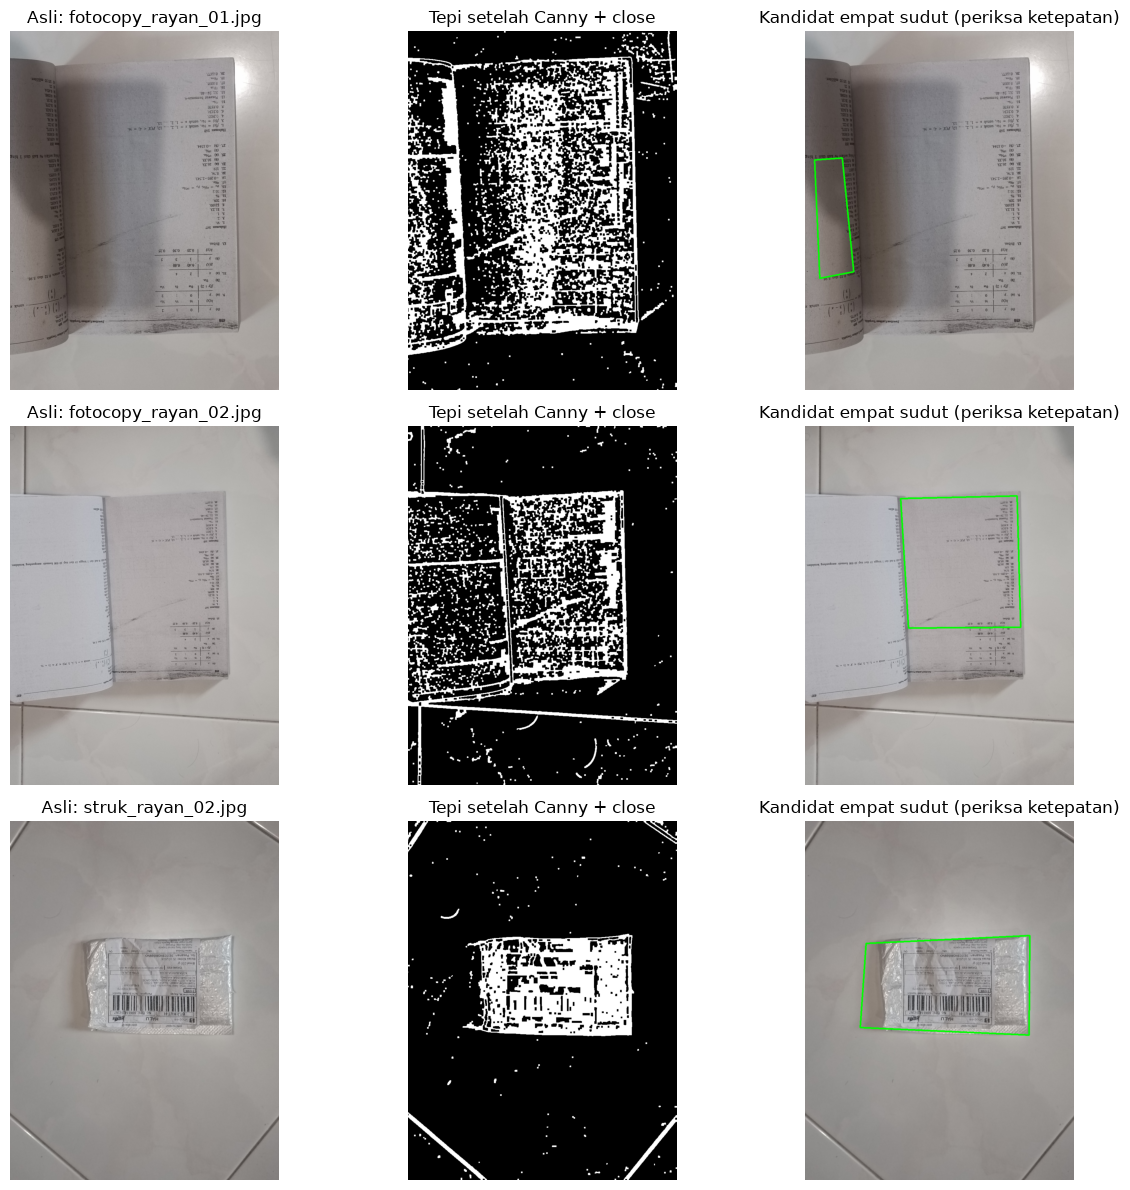

Panduan penulisan analisis: (1) kondisi foto, (2) bagian gambar yang mengganggu tepi, (3) dampak ke kontur/sudut, (4) perbaikan yang masuk akal.


In [51]:
failed = [r for r in results if not r["detected"]]
if failed:
    examples = failed[:3]
else:
    # Jika tidak ada kegagalan deteksi, periksa hingga tiga foto sulit.
    difficult_paths = [p for p in readable if normalize_category(category_for(p)) == "sulit"]
    examples = [{"filename": p.name, "path": str(p), "reason": "Periksa manual: kondisi sulit"} for p in difficult_paths[:3]]

if not examples:
    print("Belum ada contoh. Pastikan dataset memuat kategori sulit.")
else:
    fig, axes = plt.subplots(len(examples), 3, figsize=(13, 4 * len(examples)))
    if len(examples) == 1:
        axes = np.array([axes])
    for i, item in enumerate(examples):
        path = Path(item["path"])
        img = read_image(path)
        show_bgr(img, f"Asli: {path.name}", ax=axes[i, 0])
        if img is not None:
            det = detect_document_corners(img)
            show_gray(det["edges_closed"], "Tepi setelah Canny + close", ax=axes[i, 1])
            view = det["resized"].copy()
            if det["corners_small"] is not None:
                pts = det["corners_small"].astype(np.int32).reshape(-1, 1, 2)
                cv2.polylines(view, [pts], True, (0, 255, 0), 3)
                title = "Kandidat empat sudut (periksa ketepatan)"
            else:
                title = "Deteksi gagal: empat sudut tidak ditemukan"
            show_bgr(view, title, ax=axes[i, 2])
        else:
            show_gray(None, "Tidak dapat dibaca", ax=axes[i, 1])
            show_gray(None, "Tidak ada hasil", ax=axes[i, 2])
    plt.tight_layout()
    plt.show()

print("Panduan penulisan analisis: (1) kondisi foto, (2) bagian gambar yang mengganggu tepi, (3) dampak ke kontur/sudut, (4) perbaikan yang masuk akal.")

## 12. Kesimpulan

Pipeline ini menerapkan Gaussian blur dan Canny untuk menemukan tepi, findContours dan approxPolyDP untuk mencari kandidat empat sudut, getPerspectiveTransform dan warpPerspective untuk meluruskan dokumen ke kanvas rasio A4, serta Otsu dan adaptive threshold untuk menghasilkan citra biner. Kinerja aktual harus disimpulkan berdasarkan tabel evaluasi yang dihasilkan ketika seluruh dataset tersedia. Akurasi keputusan pada notebook ini membandingkan status deteksi dengan label visibilitas sudut, sehingga belum mengukur ketepatan koordinat sudut. Foto yang gagal atau meragukan tetap perlu dianalisis.

## Referensi

- OpenCV Documentation, *Image Thresholding* dan *Contours: Getting Started*. https://docs.opencv.org/ (diakses Oktober 2026).
- Modul Praktikum Visi Komputer Pertemuan 3 dan 4, materi thresholding, blur, Canny, kontur, dan approxPolyDP.
- OpenAI ChatGPT, digunakan sebagai bantuan revisi struktur notebook, debugging, dan penjelasan pipeline (Oktober 2026).